In [1]:
import os
import sys
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..', 'utility')))
os.environ["CUDA_VISIBLE_DEVICES"] = "0,1"  
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '1'  # or any {'0', '1', '2'}

from sklearn.preprocessing      import MinMaxScaler
from keras.models               import Model
from keras.layers               import Input, Conv1D, MaxPooling1D, UpSampling1D, Dense, Flatten, Reshape, ZeroPadding1D, Concatenate, Lambda, Multiply, Minimum, Maximum, LSTM, Masking
from keras.layers               import GlobalAveragePooling1D, RepeatVector
from keras.constraints          import NonNeg
from tensorflow.keras.callbacks import EarlyStopping

from preProcessingDataTEP       import PreProcessData
# from matpilotDraw               import MatPlot

import tensorflow           as tf
import numpy                as np
import pandas               as pd
import matplotlib.pyplot    as plt
import random
import warnings
import json
epochTrain      = 200

env                 = 3
seedNumber          = 805

tf.random.set_seed(seedNumber)
np.random.seed(seedNumber)
random.seed(seedNumber)

warnings.filterwarnings('ignore') 

with open('utility/modelConfig.json', 'r') as configFile:
    config = json.load(configFile)
myConfig   = config["tep"]


prePro          = PreProcessData(config=myConfig)
# -----------------------------
# Load and prepare data
# -----------------------------
allWithoutLabel      = ['D feed',                   'E Feed',                   'A Feed',                   'A and C Feed',         'Recycle',              'Purge', 
                        'Separator',                'Stripper',                 'Steam',                    'Reactor Coolant',      'Condenser Coolant',    'Agitator',                 # 12 manipulated variables
                        'msv A Feed',               'msv D Feed',               'msv E Feed',               'msv A and C Feed',     'Recycle Flow',         'Reactor Feed Rate',        # 41 measured variables
                        'Reactor Pressure',         'Reactor Temperature',      'Purge Rate',               'Product Sep Temp', 
                        'Product Sep Pressure',     'Product Sep Underflow',    'Stripper Pressure',        'Reactor Coolant Temp',
                        'Stripper Underflow',       'Stripper Temp',            'Stripper Steam Flow',      'Compressor Work',      
                        'Separator Coolant Temp',   'Component A to Reactor',   'Component B to Reactor',   'Component C to Reactor',
                        'Component D to Reactor',   'Component E to Reactor',   'Component F to Reactor',   'Component A to Purge',
                        'Component B to Purge',     'Component C to Purge',     'Component D to Purge',     'Component E to Purge',
                        'Component F to Purge',     'Component G to Purge',     'Component H to Purge',     'Component D to Product',
                        'Component E to Product',   'Component F to Product',   'Component G to Product',   'Component H to Product',
                        ]     #"rul"

reacLabel           = ['Reactor Coolant', 'Reactor Coolant Temp', 'Reactor Feed Rate', 'Reactor Pressure', 'Reactor Temperature']
sepLabel            = ['Separator', 'Product Sep Temp', 'Product Sep Underflow', 'Separator Coolant Temp', 'E Feed']
stripLabel          = ['Stripper', 'Stripper Underflow', 'E Feed', 'Component B to Reactor', 'Component F to Reactor']

reac_indices        = [allWithoutLabel.index(label) for label in reacLabel]
sep_indices         = [allWithoutLabel.index(label) for label in sepLabel]
strip_indices       = [allWithoutLabel.index(label) for label in stripLabel]
print("Reactor indices: ", reac_indices)
print("Separator indices: ", sep_indices)
print("Stripper indices: ", strip_indices)

outputDir           = os.path.expanduser(prePro.config["dataDir"])

df                  = prePro.loadDataFromH5Format(dir = outputDir, name="data/teps.h5", case="all", reduceSampleRate = True)

# ---------------------------
# Subtract time and adjust
# Remove data before time 40
for idx in df.keys():
    df[idx]         = df[idx][df[idx]["Time"] >= 40]  # Remove data before time 40
    df[idx]["Time"] = df[idx]["Time"] - 40  # Adjust time to start from 0
    df[idx]         = df[idx].reset_index(drop=True)  # Reset index after filtering

withRULData         = prePro.addRULAndEnvironment(df)

# ---------------------------
# For data
cleanData           = prePro.cleanData(   rawSignal         =   withRULData,
                                        columnName          =   allWithoutLabel,
                                        getMovingAverage    =   False,
                                        flipToDown          =   True)
# ---------------------------
# For label, flip only
cleanData           = prePro.cleanData(rawSignal            =   cleanData,
                                        columnName          =   prePro.degraLiq,
                                        getMovingAverage    =   False,
                                        flipToDown          =   True)

print(cleanData[1].head())

# ==============================
# This function is used to prepare 
# the data
# -----------------------------
def dataHandling(df, idName = 'Id', sensorUsed=None, scaler = None,curEnv = None, normalize = True):
    # -----------------------------
    # Init variables
    # sensorUsed        = ['s2','s3','s4','s7','s8','s9','s11','s12','s13','s14','s15','s17','s20','s21'] if sensorUsed is None else sensorUsed
    sensorUsed          = allWithoutLabel if sensorUsed is None else sensorUsed
    windowSize          = 30  # Fixed sequence length
    segmentedData       = []
    engineIds           = []
    beginningCycles     = []
    env                 = []

    # -----------------------------
    # Build sliding windows from each engine
    for engId in df[idName].unique():
        dfEngine        = df[df[idName] == engId]
        engineData      = dfEngine[sensorUsed].values
        for start in range(0, len(engineData) - windowSize + 1):
            window = engineData[start : start + windowSize]
            segmentedData.append(window)
            engineIds.append(engId)
            beginningCycles.append(start + 1)
            env.append(curEnv)

    segmentedData           = np.array(segmentedData)  # (N, 30, 14)
    
    # -----------------------------
    # Normalize data
    N, seqLength, numFeatures   = segmentedData.shape                               # Get the shape of the data after converting to numpy array
    if normalize:
        xFlat                       = segmentedData.reshape(N * seqLength, numFeatures)
        scaler                      = MinMaxScaler() if scaler is None else scaler
        xFlatScaled                 = scaler.fit_transform(xFlat)
        segmentedXScaled            = xFlatScaled.reshape(N, seqLength, numFeatures)
    else:
        segmentedXScaled            = segmentedData
        scaler                      = None
    return segmentedXScaled, engineIds, beginningCycles, env, seqLength, numFeatures, scaler





2025-06-28 22:36:02.499944: E tensorflow/stream_executor/cuda/cuda_blas.cc:2981] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-06-28 22:36:03.794326: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer.so.7'; dlerror: libnvinfer.so.7: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: :/home/ducan/anaconda3/envs/tensorflow2.10.0Crusher/lib/
2025-06-28 22:36:03.794431: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer_plugin.so.7'; dlerror: libnvinfer_plugin.so.7: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: :/home/ducan/anaconda3/envs/tensorflow2.10.0Crusher/lib/
2025-06-28 22:36:03.794441: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Cannot dlopen some TensorRT libraries. If you would like to use Nvidia GPU with Te

Reactor indices:  [9, 25, 17, 18, 19]
Separator indices:  [6, 21, 23, 30, 1]
Stripper indices:  [7, 26, 1, 32, 36]


Process:5852||2025-06-28 22:36:08,083-INFO [preProcessingDataTEP.py:loadDataFromH5Format():384]:Finish loading data from H5 files at case all...
Process:5852||2025-06-28 22:36:08,885-INFO [preProcessingDataTEP.py:addRULAndEnvironment():433]:Adding rul successfully...
Process:5852||2025-06-28 22:36:08,885-INFO [preProcessingDataTEP.py:cleanData():510]:Cleaning data ...
Process:5852||2025-06-28 22:36:08,886-INFO [preProcessingDataTEP.py:cleanData():530]:Flipping data at case 1
Process:5852||2025-06-28 22:36:12,594-INFO [preProcessingDataTEP.py:cleanData():530]:Flipping data at case 2
Process:5852||2025-06-28 22:36:15,589-INFO [preProcessingDataTEP.py:cleanData():530]:Flipping data at case 3
Process:5852||2025-06-28 22:36:18,105-INFO [preProcessingDataTEP.py:cleanData():530]:Flipping data at case 4
Process:5852||2025-06-28 22:36:20,574-INFO [preProcessingDataTEP.py:cleanData():530]:Flipping data at case 5
Process:5852||2025-06-28 22:36:23,294-INFO [preProcessingDataTEP.py:cleanData():530]

   Id  Time  environmentID      D feed    E Feed     A Feed  A and C Feed  \
0   1   0.0              1   99.966944  9.725330  23.318625     57.683361   
1   1   0.1              1   99.995680  9.762395  23.267178     57.835898   
2   1   0.2              1   99.994413  9.797887  23.853315     57.596908   
3   1   0.3              1  100.054304  9.750245  22.948780     57.984434   
4   1   0.4              1  100.119779  9.694650  22.757426     57.897216   

     Recycle      Purge  Separator  ...  Component H to Purge  \
0  63.890794   9.466375  33.081267  ...              0.372447   
1  63.890794  10.009741  32.952038  ...              0.482741   
2  63.890794   9.822556  32.799209  ...              0.453314   
3  63.890794   8.071345  32.587945  ...              0.479550   
4  63.890794   5.238184  32.409586  ...              0.501860   

   Component D to Product  Component E to Product  Component F to Product  \
0                0.034249                0.162189                0.08

In [2]:
# ------------------------------------
# Data handling before training
# ------------------------------------
dataEnv1    = cleanData[2]
xScaled1, engineIds1, beginningCycles1,env1, seqLength, numFeatures,_     = dataHandling(dataEnv1, curEnv = 1)
xTimeEnv1, _, _, _, _, _,_                                                = dataHandling(dataEnv1, curEnv = 1, sensorUsed=['Time'], normalize=False)  # Get time data
yRul, _, _, _, _, _, rulScaler1                                           = dataHandling(dataEnv1, curEnv = 1, sensorUsed=['rul'])  # Get RUL data
yRul1                                                                     = yRul[:,-1,:]  # Get last value of each sequence

dataEnv2    = cleanData[3]
xScaled2, engineIds2, beginningCycles2,env2, _, _, _                           = dataHandling(dataEnv2, curEnv = 2)
xTimeEnv2, _, _, _, _, _,_                                                    = dataHandling(dataEnv2, curEnv = 2, sensorUsed=['Time'], normalize=False)  # Get time data
yRul, _, _, _, _, _,rulScaler2                                                     = dataHandling(dataEnv2, curEnv = 2, sensorUsed=['rul'])  # Get RUL data
yRul2                                                                     = yRul[:,-1,:]  # Get last value of each sequence

dataEnv3    = cleanData[4]
xScaled3, engineIds3, beginningCycles3, env3,_, _,_                        = dataHandling(dataEnv3, curEnv = 3)
xTimeEnv3, _, _, _, _, _,_                                                = dataHandling(dataEnv3, curEnv = 3, sensorUsed=['Time'], normalize=False)  # Get time data
yRul, _, _, _, _, _, rulScaler3                                           = dataHandling(dataEnv3, curEnv = 3, sensorUsed=['rul'])  # Get RUL data
yRul3                                                                     = yRul[:,-1,:]  # Get last value of each sequence


# -------------------------------------
# Get the environment data
reactorEnv1      = xScaled1[:, :, reac_indices]
reactorEnv2      = xScaled2[:, :, reac_indices]
reactorEnv3      = xScaled3[:, :, reac_indices]
separatorEnv1    = xScaled1[:, :, sep_indices]
separatorEnv2    = xScaled2[:, :, sep_indices]
separatorEnv3    = xScaled3[:, :, sep_indices]
stripperEnv1     = xScaled1[:, :, strip_indices]
stripperEnv2     = xScaled2[:, :, strip_indices]
stripperEnv3     = xScaled3[:, :, strip_indices]

if env==1:
    reactorEnv1      = reactorEnv1
    separatorEnv1    = separatorEnv1
    stripperEnv1     = stripperEnv1
    xTimeEnv1        = xTimeEnv1[:,-1,:].squeeze()
    yRul1            = yRul1
    rulScaler        = rulScaler1
    engineIds1     = engineIds1

elif env==2:
    reactorEnv1      = reactorEnv2
    separatorEnv1    = separatorEnv2
    stripperEnv1     = stripperEnv2
    xTimeEnv1        = xTimeEnv2[:,-1,:].squeeze()
    yRul1            = yRul2
    rulScaler        = rulScaler2
    engineIds1     = engineIds2
elif env==3:
    reactorEnv1      = reactorEnv3
    separatorEnv1    = separatorEnv3
    stripperEnv1     = stripperEnv3
    xTimeEnv1        = xTimeEnv3[:,-1,:].squeeze()
    yRul1            = yRul3
    rulScaler        = rulScaler3
    engineIds1     = engineIds3



# allXScaled          = np.concatenate([xScaled1, xScaled2, xScaled3], axis=0)
# allYRul             = np.concatenate([yRul1, yRul2, yRul3], axis=0)
# allEngineIds        = engineIds1 + engineIds2 + engineIds3
# allBeginningCycles  = beginningCycles1 + beginningCycles2 + beginningCycles3
# # allEnv              = np.array(env1 + env2 + env3 ).reshape(-1, 1)
# allEnv              = np.array(env1 + env2 + env3 )

# ------------------------------------
print(xScaled1.shape, xScaled2.shape, xScaled3.shape)
# print(allXScaled.shape)

print(yRul1.shape, yRul2.shape, yRul3.shape)
# print(allYRul.shape)

print(len(engineIds1), len(engineIds1), len(engineIds1))
# print(len(allEngineIds))

print(len(beginningCycles1), len(beginningCycles2), len(beginningCycles3))
# print(len(allBeginningCycles))

print(len(env1), len(env2), len(env3))
# print(allEnv.shape)


print("Reactor Env 1 shape: ", reactorEnv1.shape)
print("Reactor Env 2 shape: ", reactorEnv2.shape)
print("Reactor Env 3 shape: ", reactorEnv3.shape)
print("Separator Env 1 shape: ", separatorEnv1.shape)
print("Separator Env 2 shape: ", separatorEnv2.shape)
print("Separator Env 3 shape: ", separatorEnv3.shape)
print("Stripper Env 1 shape: ", stripperEnv1.shape)
print("Stripper Env 2 shape: ", stripperEnv2.shape)
print("Stripper Env 3 shape: ", stripperEnv3.shape)


(98059, 30, 50) (99674, 30, 50) (79908, 30, 50)
(79908, 1) (99674, 1) (79908, 1)
79908 79908 79908
98059 99674 79908
98059 99674 79908
Reactor Env 1 shape:  (79908, 30, 5)
Reactor Env 2 shape:  (99674, 30, 5)
Reactor Env 3 shape:  (79908, 30, 5)
Separator Env 1 shape:  (79908, 30, 5)
Separator Env 2 shape:  (99674, 30, 5)
Separator Env 3 shape:  (79908, 30, 5)
Stripper Env 1 shape:  (79908, 30, 5)
Stripper Env 2 shape:  (99674, 30, 5)
Stripper Env 3 shape:  (79908, 30, 5)


### Reactor Env 1

The shape of last layer encoder is (None, 8, 16)
----------------------------------------========
(None, 30, 5)
----------------------------------------========
['conv1d_3']
['recon_loss']
Epoch 1/200


2025-06-28 22:36:37.901870: W tensorflow/stream_executor/gpu/asm_compiler.cc:80] Couldn't get ptxas version string: INTERNAL: Couldn't invoke ptxas --version
2025-06-28 22:36:37.902443: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] INTERNAL: Failed to launch ptxas
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.


562/562 [==============================] - 8s 10ms/step - loss: 0.1099 - recon_loss: 0.1099 - val_loss: 0.0843 - val_recon_loss: 0.0843
Epoch 2/200
562/562 [==============================] - 5s 9ms/step - loss: 0.0838 - recon_loss: 0.0838 - val_loss: 0.0839 - val_recon_loss: 0.0839
Epoch 3/200
562/562 [==============================] - 6s 10ms/step - loss: 0.0836 - recon_loss: 0.0836 - val_loss: 0.0838 - val_recon_loss: 0.0838
Epoch 4/200
562/562 [==============================] - 5s 9ms/step - loss: 0.0836 - recon_loss: 0.0836 - val_loss: 0.0837 - val_recon_loss: 0.0837
Epoch 5/200
562/562 [==============================] - 5s 10ms/step - loss: 0.0835 - recon_loss: 0.0835 - val_loss: 0.0837 - val_recon_loss: 0.0837
Epoch 6/200
562/562 [==============================] - 5s 9ms/step - loss: 0.0835 - recon_loss: 0.0835 - val_loss: 0.0837 - val_recon_loss: 0.0837
Epoch 7/200
562/562 [==============================] - 5s 9ms/step - loss: 0.0835 - recon_loss: 0.0835 - val_loss: 0.0837 - val

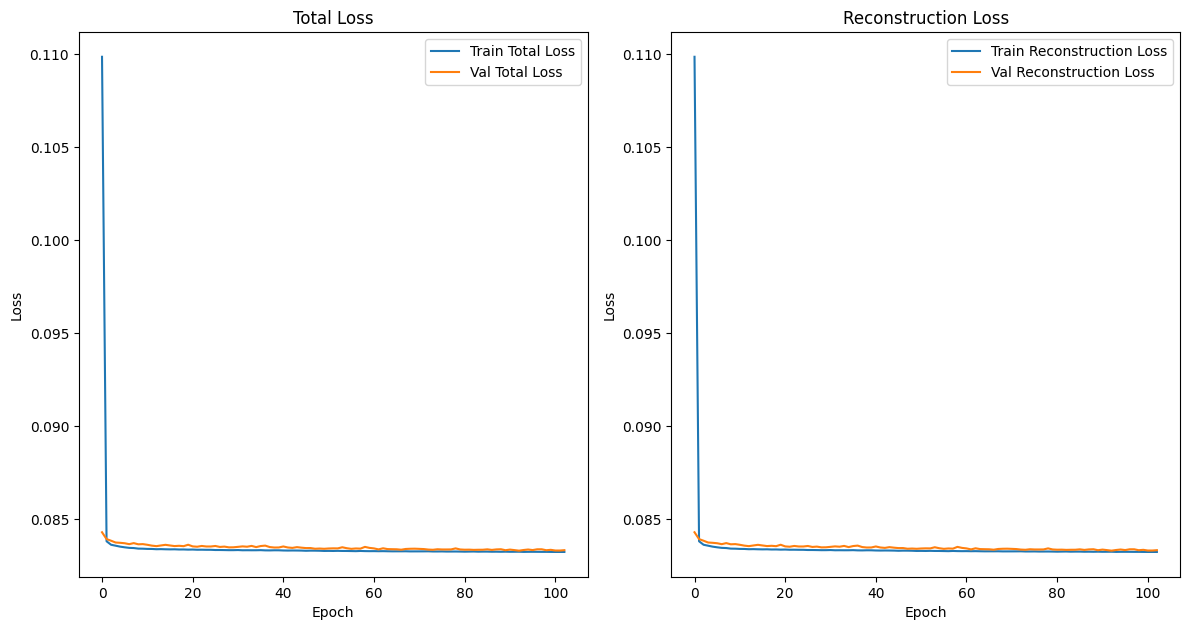

In [3]:
trainNumFeatures = 5
# ==============================
# Encoder block
# ------------------------------
inputs                      = Input(shape=(seqLength, trainNumFeatures))
x                           = Conv1D(32, 3, activation='relu', padding='same')(inputs)
x                           = MaxPooling1D(2, padding='same')(x)
x                           = Conv1D(16, 3, activation='relu', padding='same')(x)
lastAELayer                 = MaxPooling1D(2, padding='same',name='lastAELayer')(x)
x                           = GlobalAveragePooling1D()(lastAELayer)
latent                      = Dense(1, name='latent')(x)  # HI directly here

print("The shape of last layer encoder is", lastAELayer.shape)

# ==============================
# Decoder block
# -----------------------------
x           = Dense((seqLength // 4) * 16, activation='relu')(latent)  # (7 * 16)
x           = Reshape((seqLength // 4, 16))(x)  # Shape: (7, 16)
x           = UpSampling1D(2)(x)  # Shape: (14, 16)
x           = Conv1D(32, 3, activation='relu', padding='same')(x)  # Shape: (14, 32)
x           = UpSampling1D(2)(x)  # Shape: (28, 32)
x           = ZeroPadding1D(padding=(1, 1))(x)  # Pad to get (30, 32)
decoded     = Conv1D(trainNumFeatures, 3, activation='linear', padding='same')(x)  # Shape: (30, 14)

print("----------------------------------------========")
print(decoded.shape)
print("----------------------------------------========")

recon_loss      = tf.reduce_mean(tf.abs(decoded - inputs))
cnnAEModel      = Model(inputs, outputs=decoded, name='cnn_ae_model')


cnnAEModel.add_loss(recon_loss)
cnnAEModel.add_metric(recon_loss, name="recon_loss", aggregation="mean")
cnnAEModel.compile( optimizer    ='adam')  # adjust weights as needed

# ==============================
# Train the model
# ------------------------------

print(cnnAEModel.output_names)  # ['reconstruction']
print(cnnAEModel.metrics_names) # ['loss', 'mae', 'ssProbability']


early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,          # number of epochs with no improvement after which training stops
    restore_best_weights=True,
    verbose=1
)

history = cnnAEModel.fit(reactorEnv1, reactorEnv1, epochs=epochTrain, batch_size=128, validation_split=0.1, callbacks=[early_stop], verbose=1)


print(history.history.keys())


plt.figure(figsize=(12, 12))

plt.subplot(2, 2, 1)
plt.plot(history.history['loss'], label='Train Total Loss')
plt.plot(history.history['val_loss'], label='Val Total Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Total Loss')
plt.legend()

# --- Plot reconstruction loss ---
plt.subplot(2, 2, 2)
plt.plot(history.history['recon_loss'], label='Train Reconstruction Loss')
plt.plot(history.history['val_recon_loss'], label='Val Reconstruction Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Reconstruction Loss')
plt.legend()


plt.tight_layout()
plt.show()



2498/2498 [==============================] - 6s 2ms/step
[ 2.9   3.    3.1  ... 85.25 85.35 85.45]


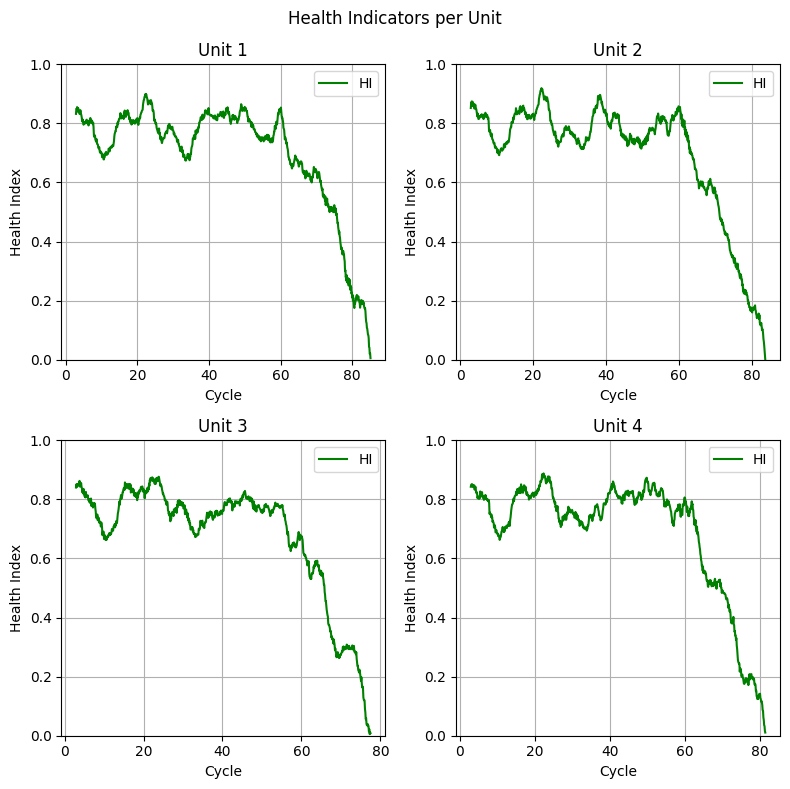

In [4]:
from utility.matpilotDraw   import MatPlot
# ==============================
# Extract latent HI values
# ------------------------------
encoderReac = Model(    inputs  =  cnnAEModel.input,
                    outputs = [cnnAEModel.get_layer('lastAELayer').output, cnnAEModel.get_layer('latent').output],  name="encoderSubModelReac")  # Extract the encoder part of the model
                                                    
_, rawHIValues      = encoderReac.predict(reactorEnv1, verbose=1)  # Get the latent values (HI) from the encoder
reacHIValues            = rawHIValues.flatten()                        # Flatten to 1D array
# hiValues            = (hiValues - hiValues.min()) / (hiValues.max() - hiValues.min())           # Normalize HI


# print(beginningCycles1)
# print(xTimeEnv1[0].shape)
print(xTimeEnv1)

dfHI                = pd.DataFrame({'env'   : np.full_like(reacHIValues, fill_value=1),
                                    'id'    : np.array(engineIds1),
                                    'cycle' : xTimeEnv1,
                                    'HI'    : -reacHIValues})              # Build dataframe for plotting


hiThresholdReac     = max(dfHI.groupby('id')['HI'].min())
upperHIReac         = max(dfHI.groupby('id')['HI'].max())
dfHI                = dfHI[dfHI['HI'] > hiThresholdReac]                                          # Filter out engines with HI > threshold

dfHI["HI"]          = (dfHI["HI"] - hiThresholdReac) / (upperHIReac - hiThresholdReac)           # Normalize HI


plot1 = MatPlot()
plot1.plot_HI_by_id(
    dfHI,
    hi_columns=["HI"],
    num_rows=2,
    num_cols=2,
    colors=['green'],
    title="Health Indicators per Unit",
    y_lim=[0, 1]  # adjust if needed
)





### Sep Env 1

The shape of last layer encoder is (None, 8, 16)
----------------------------------------========
(None, 30, 5)
----------------------------------------========
['conv1d_7']
['recon_loss']
Epoch 1/200
562/562 [==============================] - 7s 10ms/step - loss: 0.0839 - recon_loss: 0.0839 - val_loss: 0.0379 - val_recon_loss: 0.0379
Epoch 2/200
562/562 [==============================] - 6s 10ms/step - loss: 0.0380 - recon_loss: 0.0380 - val_loss: 0.0373 - val_recon_loss: 0.0373
Epoch 3/200
562/562 [==============================] - 6s 11ms/step - loss: 0.0380 - recon_loss: 0.0380 - val_loss: 0.0375 - val_recon_loss: 0.0375
Epoch 4/200
562/562 [==============================] - 6s 10ms/step - loss: 0.0379 - recon_loss: 0.0379 - val_loss: 0.0373 - val_recon_loss: 0.0373
Epoch 5/200
562/562 [==============================] - 6s 10ms/step - loss: 0.0379 - recon_loss: 0.0379 - val_loss: 0.0375 - val_recon_loss: 0.0375
Epoch 6/200
562/562 [==============================] - 6s 11ms/step - l

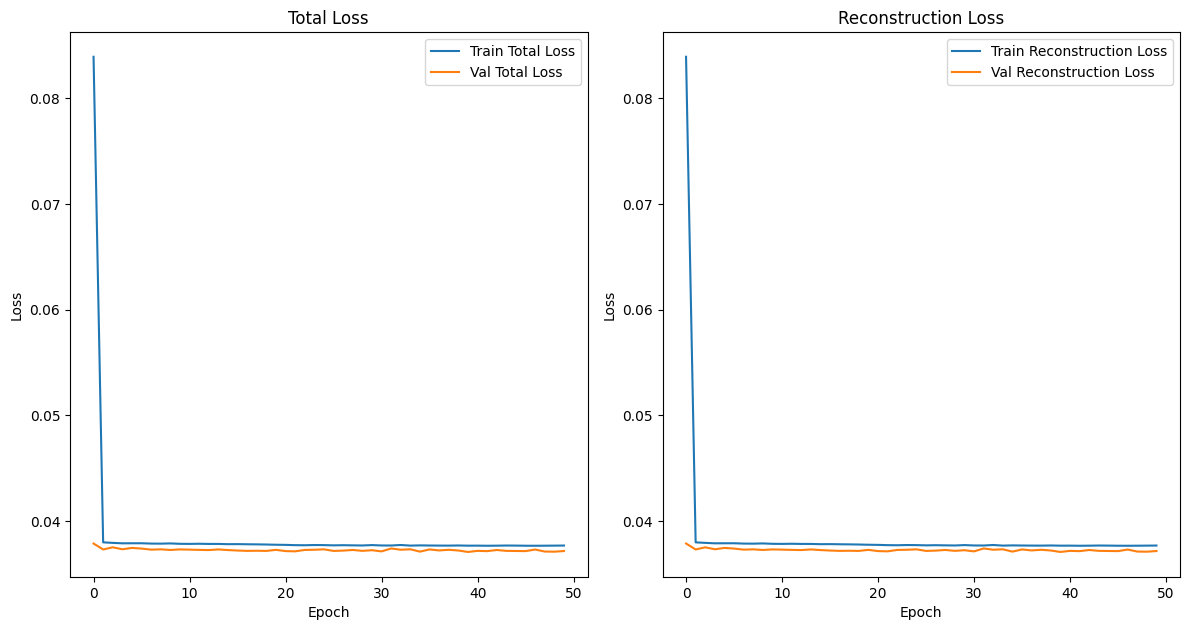

In [5]:
trainNumFeatures = 5
# ==============================
# Encoder block
# ------------------------------
inputs                      = Input(shape=(seqLength, trainNumFeatures))
x                           = Conv1D(32, 3, activation='relu', padding='same')(inputs)
x                           = MaxPooling1D(2, padding='same')(x)
x                           = Conv1D(16, 3, activation='relu', padding='same')(x)
lastAELayer                 = MaxPooling1D(2, padding='same',name='lastAELayer')(x)
x                           = GlobalAveragePooling1D()(lastAELayer)
latent                      = Dense(1, name='latent')(x)  # HI directly here

print("The shape of last layer encoder is", lastAELayer.shape)

# ==============================
# Decoder block
# -----------------------------
x           = Dense((seqLength // 4) * 16, activation='relu')(latent)  # (7 * 16)
x           = Reshape((seqLength // 4, 16))(x)  # Shape: (7, 16)
x           = UpSampling1D(2)(x)  # Shape: (14, 16)
x           = Conv1D(32, 3, activation='relu', padding='same')(x)  # Shape: (14, 32)
x           = UpSampling1D(2)(x)  # Shape: (28, 32)
x           = ZeroPadding1D(padding=(1, 1))(x)  # Pad to get (30, 32)
decoded     = Conv1D(trainNumFeatures, 3, activation='linear', padding='same')(x)  # Shape: (30, 14)

print("----------------------------------------========")
print(decoded.shape)
print("----------------------------------------========")

recon_loss      = tf.reduce_mean(tf.abs(decoded - inputs))
cnnAEModel      = Model(inputs, outputs=decoded, name='cnn_ae_model')


cnnAEModel.add_loss(recon_loss)
cnnAEModel.add_metric(recon_loss, name="recon_loss", aggregation="mean")
cnnAEModel.compile( optimizer    ='adam')  # adjust weights as needed

# ==============================
# Train the model
# ------------------------------

print(cnnAEModel.output_names)  # ['reconstruction']
print(cnnAEModel.metrics_names) # ['loss', 'mae', 'ssProbability']


early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,          # number of epochs with no improvement after which training stops
    restore_best_weights=True,
    verbose=1
)


history = cnnAEModel.fit(separatorEnv1, separatorEnv1, epochs=epochTrain, batch_size=128, validation_split=0.1, callbacks=[early_stop], verbose=1)


print(history.history.keys())


plt.figure(figsize=(12, 12))

plt.subplot(2, 2, 1)
plt.plot(history.history['loss'], label='Train Total Loss')
plt.plot(history.history['val_loss'], label='Val Total Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Total Loss')
plt.legend()

# --- Plot reconstruction loss ---
plt.subplot(2, 2, 2)
plt.plot(history.history['recon_loss'], label='Train Reconstruction Loss')
plt.plot(history.history['val_recon_loss'], label='Val Reconstruction Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Reconstruction Loss')
plt.legend()


plt.tight_layout()
plt.show()



2498/2498 [==============================] - 6s 2ms/step


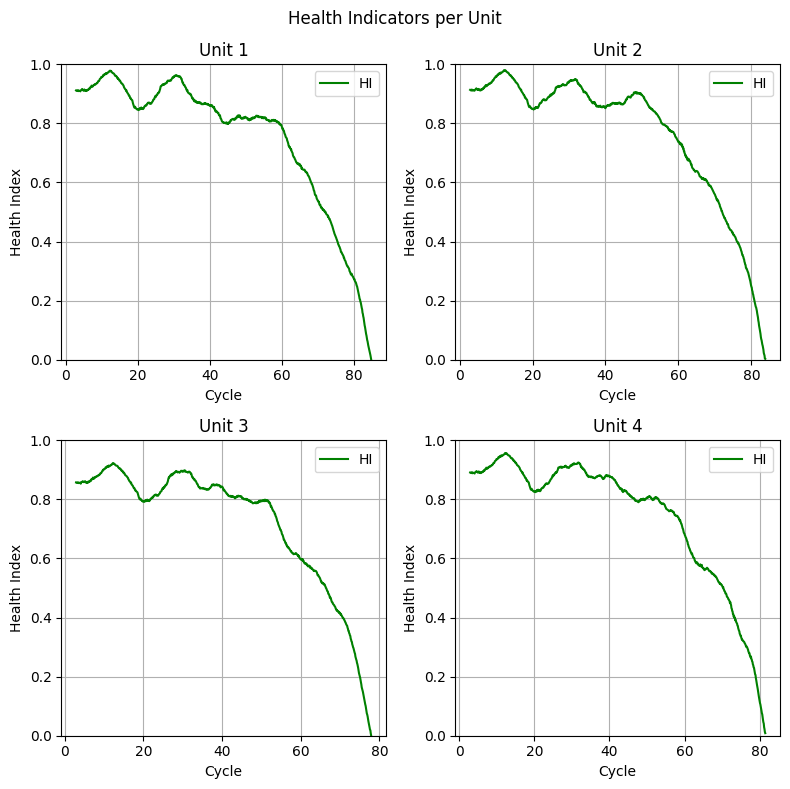

In [6]:
from utility.matpilotDraw   import MatPlot
# ==============================
# Extract latent HI values
# ------------------------------
encoderSep = Model(    inputs  =  cnnAEModel.input,
                    outputs = [cnnAEModel.get_layer('lastAELayer').output, cnnAEModel.get_layer('latent').output],  name="encoderSubmodelSep")

_, rawHIValues      = encoderSep.predict(separatorEnv1, verbose=1)  # Get the latent values (HI) from the encoder
sepHIValues            = rawHIValues.flatten()                        # Flatten to 1D array
# hiValues            = (hiValues - hiValues.min()) / (hiValues.max() - hiValues.min())           # Normalize HI

# print(hiValues.shape)
# print(reactorEnv1.shape)
# print(engineIds1.shape)
# print(beginningCycles1.shape)


dfHI                = pd.DataFrame({'env'   : np.full_like(sepHIValues, fill_value=1),
                                    'id'    : np.array(engineIds1),
                                    'cycle' : np.array(xTimeEnv1),
                                    'HI'    : -sepHIValues})              # Build dataframe for plotting


hiThresholdSep         = max(dfHI.groupby('id')['HI'].min())
upperHISep             = max(dfHI.groupby('id')['HI'].max())
dfHI                = dfHI[dfHI['HI'] > hiThresholdSep]                                          # Filter out engines with HI > threshold

dfHI["HI"]          = (dfHI["HI"] - hiThresholdSep) / (upperHISep - hiThresholdSep)           # Normalize HI


plot1 = MatPlot()
plot1.plot_HI_by_id(
    dfHI,
    hi_columns=["HI"],
    num_rows=2,
    num_cols=2,
    colors=['green'],
    title="Health Indicators per Unit",
    y_lim=[0, 1]  # adjust if needed
)






### Stripper Env1

The shape of last layer encoder is (None, 8, 16)
----------------------------------------========
(None, 30, 5)
----------------------------------------========
['conv1d_11']
['recon_loss']
Epoch 1/200
562/562 [==============================] - 7s 10ms/step - loss: 0.0939 - recon_loss: 0.0939 - val_loss: 0.0433 - val_recon_loss: 0.0433
Epoch 2/200
562/562 [==============================] - 5s 10ms/step - loss: 0.0437 - recon_loss: 0.0437 - val_loss: 0.0430 - val_recon_loss: 0.0430
Epoch 3/200
562/562 [==============================] - 5s 9ms/step - loss: 0.0435 - recon_loss: 0.0435 - val_loss: 0.0427 - val_recon_loss: 0.0427
Epoch 4/200
562/562 [==============================] - 5s 10ms/step - loss: 0.0434 - recon_loss: 0.0434 - val_loss: 0.0426 - val_recon_loss: 0.0426
Epoch 5/200
562/562 [==============================] - 5s 9ms/step - loss: 0.0434 - recon_loss: 0.0434 - val_loss: 0.0426 - val_recon_loss: 0.0426
Epoch 6/200
562/562 [==============================] - 6s 10ms/step - lo

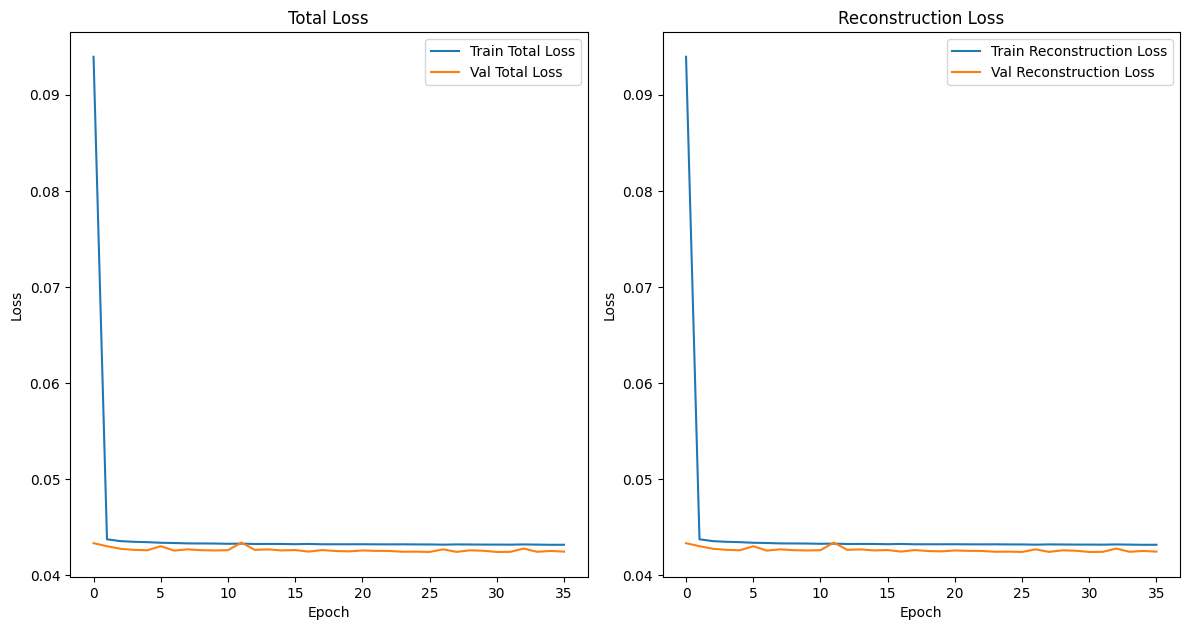

In [7]:
trainNumFeatures = 5
# ==============================
# Encoder block
# ------------------------------
inputs                      = Input(shape=(seqLength, trainNumFeatures))
x                           = Conv1D(32, 3, activation='relu', padding='same')(inputs)
x                           = MaxPooling1D(2, padding='same')(x)
x                           = Conv1D(16, 3, activation='relu', padding='same')(x)
lastAELayer                 = MaxPooling1D(2, padding='same',name='lastAELayer')(x)
x                           = GlobalAveragePooling1D()(lastAELayer)
latent                      = Dense(1, name='latent')(x)  # HI directly here

print("The shape of last layer encoder is", lastAELayer.shape)

# ==============================
# Decoder block
# -----------------------------
x           = Dense((seqLength // 4) * 16, activation='relu')(latent)  # (7 * 16)
x           = Reshape((seqLength // 4, 16))(x)  # Shape: (7, 16)
x           = UpSampling1D(2)(x)  # Shape: (14, 16)
x           = Conv1D(32, 3, activation='relu', padding='same')(x)  # Shape: (14, 32)
x           = UpSampling1D(2)(x)  # Shape: (28, 32)
x           = ZeroPadding1D(padding=(1, 1))(x)  # Pad to get (30, 32)
decoded     = Conv1D(trainNumFeatures, 3, activation='linear', padding='same')(x)  # Shape: (30, 14)

print("----------------------------------------========")
print(decoded.shape)
print("----------------------------------------========")

recon_loss      = tf.reduce_mean(tf.abs(decoded - inputs))
cnnAEModel      = Model(inputs, outputs=decoded, name='cnn_ae_model')


cnnAEModel.add_loss(recon_loss)
cnnAEModel.add_metric(recon_loss, name="recon_loss", aggregation="mean")
cnnAEModel.compile( optimizer    ='adam')  # adjust weights as needed

# ==============================
# Train the model
# ------------------------------

print(cnnAEModel.output_names)  # ['reconstruction']
print(cnnAEModel.metrics_names) # ['loss', 'mae', 'ssProbability']

early_stop = EarlyStopping(
    monitor='val_loss',    
    patience=10,          # number of epochs with no improvement after which training stops
    restore_best_weights=True,
    verbose=1
)

history = cnnAEModel.fit(stripperEnv1, stripperEnv1, epochs=epochTrain, batch_size=128, validation_split=0.1, callbacks=[early_stop], verbose=1)


print(history.history.keys())


plt.figure(figsize=(12, 12))

plt.subplot(2, 2, 1)
plt.plot(history.history['loss'], label='Train Total Loss')
plt.plot(history.history['val_loss'], label='Val Total Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Total Loss')
plt.legend()

# --- Plot reconstruction loss ---
plt.subplot(2, 2, 2)
plt.plot(history.history['recon_loss'], label='Train Reconstruction Loss')
plt.plot(history.history['val_recon_loss'], label='Val Reconstruction Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Reconstruction Loss')
plt.legend()


plt.tight_layout()
plt.show()



2498/2498 [==============================] - 7s 3ms/step


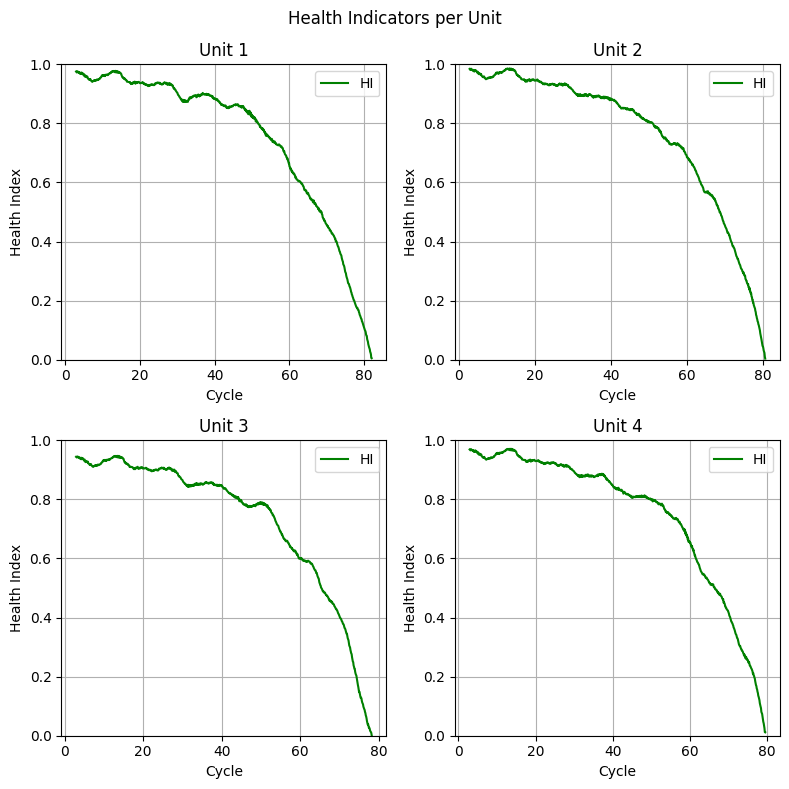

In [8]:
from utility.matpilotDraw   import MatPlot
# ==============================
# Extract latent HI values
# ------------------------------
encoderStrip = Model(    inputs  =  cnnAEModel.input,
                    outputs = [cnnAEModel.get_layer('lastAELayer').output, cnnAEModel.get_layer('latent').output],  name="encoderSubmodelStrip")

_, rawHIValues      = encoderStrip.predict(stripperEnv1, verbose=1)  # Get the latent values (HI) from the encoder
stripHIValues            = rawHIValues.flatten()                        # Flatten to 1D array
# hiValues            = (hiValues - hiValues.min()) / (hiValues.max() - hiValues.min())           # Normalize HI

# print(hiValues.shape)
# print(reactorEnv1.shape)
# print(engineIds1.shape)
# print(beginningCycles1.shape)


dfHI                = pd.DataFrame({'env'   : np.full_like(stripHIValues, fill_value=1),
                                    'id'    : np.array(engineIds1),
                                    'cycle' : np.array(xTimeEnv1),
                                    'HI'    : stripHIValues})              # Build dataframe for plotting


hiThresholdStrip         = max(dfHI.groupby('id')['HI'].min())
upperHIStrip             = max(dfHI.groupby('id')['HI'].max())
dfHI                    = dfHI[dfHI['HI'] > hiThresholdStrip]                              # Filter out engines with HI > threshold

dfHI["HI"]              = (dfHI["HI"] - hiThresholdStrip) / (upperHIStrip - hiThresholdStrip)           # Normalize HI


plot1 = MatPlot()
plot1.plot_HI_by_id(
    dfHI,
    hi_columns=["HI"],
    num_rows=2,
    num_cols=2,
    colors=['green'],
    title="Health Indicators per Unit",
    y_lim=[0, 1]  # adjust if needed
)





#### TEST FOR PAPER

        id  cycle    reacHI     sepHI   stripHI     sysHI
0        1   2.90  0.934926  0.899544  0.975725  0.899544
1        1   3.00  0.945557  0.898611  0.974086  0.898611
2        1   3.10  0.944917  0.897456  0.972411  0.897456
3        1   3.20  0.949547  0.897708  0.975753  0.897708
4        1   3.30  0.940431  0.900260  0.976671  0.900260
...    ...    ...       ...       ...       ...       ...
79840  100  78.75  0.500210  0.077657  0.035806  0.035806
79841  100  78.85  0.498586  0.066586  0.029372  0.029372
79842  100  78.95  0.494253  0.061853  0.014839  0.014839
79843  100  79.05  0.512165  0.054370  0.010437  0.010437
79844  100  79.15  0.501312  0.047694  0.006322  0.006322

[76029 rows x 6 columns]


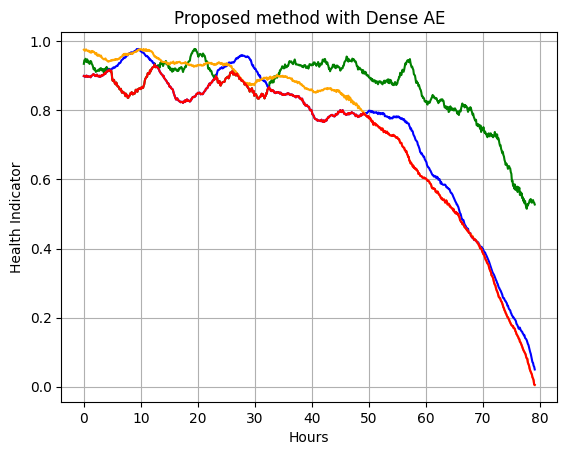

In [9]:
# print(dfHIAll)
# ==============================
# Move all HI to the same peak

dfHIAll          = pd.DataFrame({
                                    'id'            : np.array(engineIds1),
                                    'cycle'         : xTimeEnv1,
                                    # 'systemHI'      : sysHi.flatten(),
                                    'reacHI'        : -reacHIValues,
                                    'sepHI'         : -sepHIValues,
                                    'stripHI'       : stripHIValues,
                                    })              # Build dataframe for plotting



hiColumns          = ['reacHI', 'sepHI', 'stripHI']
globalMax           = dfHIAll.groupby('id')[hiColumns].max().max(axis = 1).reset_index(name='globalMax')   # Get the global maximum for each ids
maxPerIdEachCol     = dfHIAll.groupby('id')[hiColumns].max().reset_index()                                 # Get the maximum value for each column across all ids

shiftMatrix = pd.DataFrame({    'reacHI': globalMax['globalMax'] -  maxPerIdEachCol['reacHI'],
                                'sepHI':  globalMax['globalMax'] -  maxPerIdEachCol['sepHI'],
                                'stripHI': globalMax['globalMax'] - maxPerIdEachCol['stripHI'],
                            })                                                                             # Create a shift matrix to adjust the HI values

dfHIAll[hiColumns] =  dfHIAll.groupby('id')[hiColumns].apply(lambda group: group + shiftMatrix.loc[group.name-1,:])  # Adjust the HI values by adding the shift matrix


upperHIs            = max(globalMax['globalMax'])                                                           # Use the global maximum for normalization
hiThreshold         = max(dfHIAll.groupby('id')['stripHI'].min())


dfHIAll             = dfHIAll[dfHIAll['stripHI'] > hiThreshold]                                             # Filter out engines with HI > threshold

dfHIAll[hiColumns]  = (dfHIAll[hiColumns] - hiThreshold) / (upperHIs - hiThreshold)           # Normalize HI


dfHIAll["sysHI"]    = dfHIAll[hiColumns].min(axis=1)  # Calculate the system HI as the mean of the individual HIs
print(dfHIAll)

dfHIAll["cycle"] = dfHIAll["cycle"] - dfHIAll["cycle"].min()  # Normalize cycle to start from 0


# plot = MatPlot()
# plot.plot_HI_by_id(
#     dfHIAll,
#     hi_columns=["reacHI", "sepHI", "stripHI", "sysHI"],
#     num_rows=2,
#     num_cols=2,
#     colors=['green', 'blue', 'orange', 'red'],
#     title="Health Indicators per Unit",
#     y_lim=[0, 1]  # adjust if needed
# )

plot2 = MatPlot()
drawData = dfHIAll[dfHIAll["id"] == 1]  # Filter for a specific engine ID, e.g., 1
plot2.draw2DMultipleY(xCoor =   drawData["cycle"], 
                      yCoor =   [drawData["reacHI"], drawData["sepHI"], drawData["stripHI"], drawData["sysHI"]],
                      color = ["green","blue","orange","red"],
                      useLegend= False,
                      title = "Proposed method with Dense AE",
                      xLabel = "Hours",
                      yLabel= "Health Indicator",)

### System

In [ ]:
# ============================
# Freeze the encoder
# ----------------------------
print("==========================")
print("           Encoder          ")
print("==========================")
encoderReac.summary()
for layer in encoderReac.layers:
    layer.trainable = False
for layer in encoderSep.layers:
    layer.trainable = False
for layer in encoderStrip.layers:
    layer.trainable = False

# ============================
# The loss function for HI selection
# ----------------------------
def selection_entropy_loss(y_true, y_pred):
    """
    y_pred: hiMatrixOutput -> shape (None, 3)
    We ignore y_true because we don't have a label for it.
    This returns the negative sum(p * log p).
    """
    # Add a small constant (1e-10) inside the log to avoid log(0).
    # The shape of this expression is (batch_size,).
    neg_entropy = -tf.reduce_sum(y_pred * tf.math.log(y_pred + 1e-10), axis=-1)
    return neg_entropy



dfHI["HI"]          = (dfHI["HI"] - hiThresholdReac) / (upperHIReac - hiThresholdReac) 

# ===============================
# MODEL
# ===============================
input1              = Input(shape=(seqLength, trainNumFeatures))
input2              = Input(shape=(seqLength, trainNumFeatures))
input3              = Input(shape=(seqLength, trainNumFeatures))

inputRUL1, HI1 = encoderReac(input1)
inputRUL2, HI2 = encoderSep(input2)
inputRUL3, HI3 = encoderStrip(input3)

HI1 = (-HI1 - hiThresholdReac)/(upperHIReac - hiThresholdReac) 
HI2 = (-HI2 - hiThresholdSep)/(upperHISep - hiThresholdSep)
HI3 = (HI3 - hiThresholdStrip)/(upperHIStrip - hiThresholdStrip)

flatInRUL1          = Flatten()(inputRUL1)  # Shape: (32, 40)
flatInRUL2          = Flatten()(inputRUL2)  # Shape: (32, 40)
flatInRUL3          = Flatten()(inputRUL3)  # Shape: (32, 40)
hiSelectionInput    = Concatenate(axis=-1)([flatInRUL1, flatInRUL2, flatInRUL3])

# ------------------------------
# Create the HI selection matrix
# ------------------------------
x                   = Dense(24, activation="relu")(hiSelectionInput)
x                   = Dense(16, activation="relu")(x)
selection_logits    = Dense(3, activation=None, name="Selection_Logits")(x)
hiMatrixOutput      = Lambda(lambda x: tf.nn.softmax(x / 1), name="Selection_Output")(selection_logits)  # Softmax with τ=0.1 for sharper selection

# ------------------------------
# Create min, max and linear HI
# ------------------------------
minSysHi        = Minimum()([HI1, HI2, HI3])
maxSysHi        = Maximum()([HI1, HI2, HI3])
linearSysHi     = Minimum()([Maximum()([HI1, HI2]), HI3])


sysConcatenatedHi   = tf.keras.layers.Concatenate(axis=-1, name="sysConcatenatedHi")([minSysHi, maxSysHi, linearSysHi])
selected_HI         = Multiply(name="Selected_HI")([hiMatrixOutput, sysConcatenatedHi])
sysHi               = Lambda(lambda x: tf.reduce_sum(x, axis=-1, keepdims=True), name="Final_HI")(selected_HI)            # Final HI (ensuring only one HI contributes to output)

# ------------------------------
# RUL
# ------------------------------
concatenatedRULInput    = Concatenate(axis=-1)([inputRUL1, inputRUL2, inputRUL3])
rulLayer1               = LSTM(32, return_sequences=True)(concatenatedRULInput)
rulLayer2               = LSTM(16, return_sequences=True)(rulLayer1)
rulLayer3               = LSTM(3, return_sequences=False)(rulLayer2)
rulLayer4               = Concatenate(axis=-1)([rulLayer3, sysHi])
rul                     = tf.keras.layers.Dense(1, activation='linear', name = "RUL_Output")(rulLayer4)

# ------------------------------
# Create the model
# ------------------------------
sysModel = Model(inputs=[input1, input2, input3], outputs=[hiMatrixOutput, sysHi,rul])

sysModel.compile(optimizer  =       'adam',
                loss        =   {   "Selection_Output"  : selection_entropy_loss,
                                    "Final_HI"          : "mse",
                                    "RUL_Output"        : "mse"},
                loss_weights=   {   "Selection_Output"  : 0.1,  # e.g. a small coefficient
                                    "Final_HI"          : 0.0,  # no label for HI => set to 0 or 0.01 if you want
                                    "RUL_Output"        : 1.0},      
                )
print("==========================")
print("         System MODEL          ")
print("==========================")
sysModel.summary()

dummy_sel = np.zeros_like(yRul1)
sysModel.fit([reactorEnv1, separatorEnv1, stripperEnv1], [dummy_sel,dummy_sel, yRul1], epochs=epochTrain, batch_size=128, validation_split=0.1, verbose=1)


# [hiMatrixOutput, sysHi, rul] = sysModel.predict([xScaled1, xScaled2, xScaled3])
# print(hiMatrixOutput)



           Encoder          
Model: "encoderSubModelReac"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 30, 5)]           0         
                                                                 
 conv1d (Conv1D)             (None, 30, 32)            512       
                                                                 
 max_pooling1d (MaxPooling1D  (None, 15, 32)           0         
 )                                                               
                                                                 
 conv1d_1 (Conv1D)           (None, 15, 16)            1552      
                                                                 
 lastAELayer (MaxPooling1D)  (None, 8, 16)             0         
                                                                 
 global_average_pooling1d (G  (None, 16)               0         
 lobalAveragePooli

In [ ]:
_, reacHI   = encoderReac.predict(reactorEnv1)
reacHI      = reacHI.flatten()  # Flatten to 1D array

_, sepHI    = encoderSep.predict(separatorEnv1)
sepHI       = sepHI.flatten()  # Flatten to 1D array

_, stripHI   = encoderStrip.predict(stripperEnv1)
stripHI      = stripHI.flatten()  # Flatten to 1D array

[hiMatrixOutput, sysHi, rul] = sysModel.predict([reactorEnv1, separatorEnv1, stripperEnv1])

print(hiMatrixOutput)


2498/2498 [==============================] - 10s 3ms/step
[[1.4021262e-30 4.6331851e-31 1.0000000e+00]
 [1.2941258e-30 4.2932420e-31 1.0000000e+00]
 [1.0966356e-30 3.6494974e-31 1.0000000e+00]
 ...
 [1.0994412e-09 8.2464580e-10 1.0000000e+00]
 [1.6034686e-09 1.2135863e-09 1.0000000e+00]
 [1.0543176e-09 7.9215762e-10 1.0000000e+00]]


In [ ]:
print("Reactor HI values: ", reacHI)

print("Reactor HI shape: ", reacHI.shape)
print("Separator HI shape: ", sepHI.shape)
print("Stripper HI shape: ", stripHI.shape)

Reactor HI values:  [-0.6515285  -0.6645031  -0.6645467  ...  0.0684897   0.06487089
  0.07876182]
Reactor HI shape:  (79908,)
Separator HI shape:  (79908,)
Stripper HI shape:  (79908,)


0         2.90
1         3.00
2         3.10
3         3.20
4         3.30
         ...  
79903    85.05
79904    85.15
79905    85.25
79906    85.35
79907    85.45
Name: cycle, Length: 79908, dtype: float64


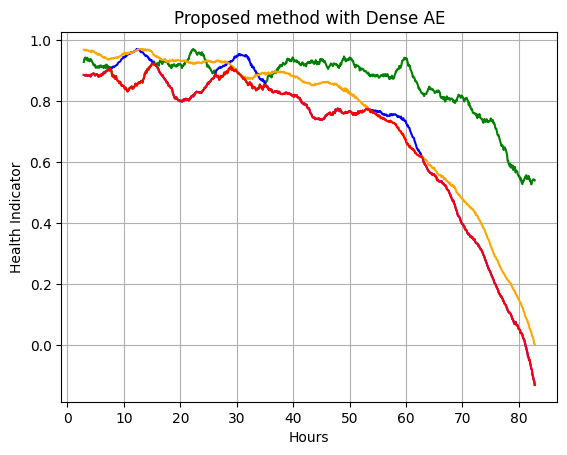

In [ ]:

dfHI                = pd.DataFrame({
                                    'id'            : np.array(engineIds1),
                                    'cycle'         : xTimeEnv1,
                                    'systemHI'      : sysHi.flatten(),
                                    'reacHI'     : -reacHI.flatten(),
                                    'sepHI'         : -sepHI.flatten(),
                                    'stripHI'       : stripHI.flatten(),
                                    })              # Build dataframe for plotting


print(dfHI["cycle"])

dfHI.to_excel('noTrendCNN1D.xlsx', index=False)

# hiThreshold         = max(dfHI.groupby('id')['systemHI'].min())
# upperHI             = max(dfHI.groupby('id')['systemHI'].max())
# dfHI                = dfHI[dfHI['systemHI'] > hiThreshold]                                          # Filter out engines with HI > threshold

# dfHI["systemHI"]         = (dfHI["systemHI"] - hiThreshold) / (upperHI - hiThreshold)           # Normalize HI
dfHI["reacHI"]           = (dfHI["reacHI"] - hiThresholdReac) / (upperHIReac - hiThresholdReac)
dfHI["sepHI"]            = (dfHI["sepHI"] - hiThresholdSep) / (upperHISep - hiThresholdSep)
dfHI["stripHI"]          = (dfHI["stripHI"] - hiThresholdStrip) / (upperHIStrip - hiThresholdStrip)

# plot1 = MatPlot()
# plot1.plot_HI_by_id(
#     dfHI,
#     hi_columns=["reacHI", "sepHI", "stripHI", "systemHI"],
#     num_rows=2,
#     num_cols=2,
#     colors=['green', 'blue', 'orange', 'red'],
#     title="Health Indicators per Unit",
#     y_lim=[0, 1]  # adjust if needed
# )


plot2 = MatPlot()
drawData = dfHIAll[dfHIAll["id"] == 1]  # Filter for a specific engine ID, e.g., 1
plot2.draw2DMultipleY(xCoor =   drawData["cycle"], 
                      yCoor =   [drawData["reacHI"], drawData["sepHI"], drawData["stripHI"], drawData["sysHI"]],
                      color = ["green","blue","orange","red"],
                      useLegend= False,
                      title = "Proposed method with Dense AE",
                      xLabel = "Hours",
                      yLabel= "Health Indicator",)


#### Evaluate the model

In [ ]:
from evaluationFunction import compute_average_hi_metrics

compMetrics = compute_average_hi_metrics(dfHI, hiCol="reacHI")
print("------------------ Reactor -----------------")
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

compMetrics = compute_average_hi_metrics(dfHI, hiCol="sepHI")
print("------------------ Separator -----------------")
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

compMetrics = compute_average_hi_metrics(dfHI, hiCol="stripHI")
print("------------------ Stripper -----------------")
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

compMetrics = compute_average_hi_metrics(dfHI, hiCol="systemHI")
print("------------------ System -----------------")
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

------------------ Reactor -----------------
Average Robustness: 0.47378463
Average Trendability: 0.731391137007799
Average Monotonicity: 0.25075019762845846
------------------ Separator -----------------
Average Robustness: 0.46083695
Average Trendability: 0.8391312412840217
Average Monotonicity: 0.4552648221343874
------------------ Stripper -----------------
Average Robustness: 0.45442578
Average Trendability: 0.8768895818727621
Average Monotonicity: 0.7205645586297762
------------------ System -----------------
Average Robustness: 0.45599285
Average Trendability: 0.8554570068248337
Average Monotonicity: 0.5875625823451911


In [ ]:
print(rul.shape)
print(rul)
print(yRul1.shape)
print(yRul1)

(79908, 1)
[[0.9442065 ]
 [0.94375205]
 [0.94622415]
 ...
 [0.0036532 ]
 [0.00131822]
 [0.00206229]]
(79908, 1)
[[0.9580974 ]
 [0.95696489]
 [0.95583239]
 ...
 [0.00226501]
 [0.0011325 ]
 [0.        ]]


In [ ]:
rulPredictionsOrginal   = rulScaler.inverse_transform(rul)
orginalSysRUL           = rulScaler.inverse_transform(yRul1.reshape(-1, 1))

rmse                    = np.sqrt(np.mean((rulPredictionsOrginal - orginalSysRUL) ** 2))

# Calculate mean RMSE across 100 units
mean_rmse = np.mean(rmse)

print("RMSE of RUL predictions:", mean_rmse)

RMSE of RUL predictions: 1.0835257690900628
